# What Makes a Steam Game Well-Reviewed?
STA 4724 Final Project. Runs top to bottom. Needs `data/games.csv` (Kaggle) in the repo's `data/` folder.

## 1. Clean the data
Runs `src/clean_steam.py` and writes `data/steam_clean.csv`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
os.chdir('..')  # run from repo root
from src import clean_steam as cs

df = cs.load_raw(cs.RAW_PATH)
print('raw:', df.shape)
df = cs.filter_games(df)
df = cs.build_response(df)
df = cs.recover_list_price(df)
df = cs.build_features(df)
df = cs.split_and_save(df)
print('clean:', df.shape)
df.split.value_counts()

raw: (125855, 40)


clean: (30624, 38)


split
train    24499
test      6125
Name: count, dtype: int64

## 2. Quick checks (should match Table 1 in the report)

In [2]:
g = [c for c in df.columns if c.startswith('genre_')]
print('well-reviewed:', round(df.well_reviewed.mean(), 3))
print('median list price:', df.list_price.median(), '| free:', round(df.free.mean(), 3))
print('genre columns:', len(g), '| indie:', round(df.indie.mean(), 3), '| multiplayer:', round(df.multiplayer.mean(), 3))
print('median languages:', df.n_languages.median(), '| years:', df.release_year.min(), '-', df.release_year.max())

well-reviewed: 0.551
median list price: 6.99 | free: 0.133
genre columns: 27 | indie: 0.826 | multiplayer: 0.253
median languages: 3.0 | years: 1997 - 2025


## 3. Models
Tunes logistic regression, a decision tree and a random forest with 5-fold stratified CV on the training split, then evaluates once on the test split. Takes about a minute. Also saves the model the Streamlit app uses.

In [3]:
%run src/models.py

train 24,499 | test 6,125 | features 32


Majority baseline      CV AUC 0.5000  {'model': DummyClassifier()}


Logistic regression    CV AUC 0.6494  {'model__C': 1}


Decision tree          CV AUC 0.6702  {'model__max_depth': 12, 'model__min_samples_leaf': 100}


Random forest          CV AUC 0.6950  {'model__max_depth': 16, 'model__min_samples_leaf': 10}


              model  cv_auc  test_auc  test_f1  test_accuracy
  Majority baseline  0.5000    0.5000   0.7108         0.5513
Logistic regression  0.6494    0.6441   0.6830         0.6078
      Decision tree  0.6702    0.6696   0.6883         0.6297
      Random forest  0.6950    0.6922   0.7107         0.6477


app model: Random forest


## 4. Results

,model,cv_auc,test_auc,test_f1,test_accuracy
0,Majority baseline,0.5000,0.5000,0.7108,0.5513
1,Logistic regression,0.6494,0.6441,0.6830,0.6078
2,Decision tree,0.6702,0.6696,0.6883,0.6297
3,Random forest,0.6950,0.6922,0.7107,0.6477


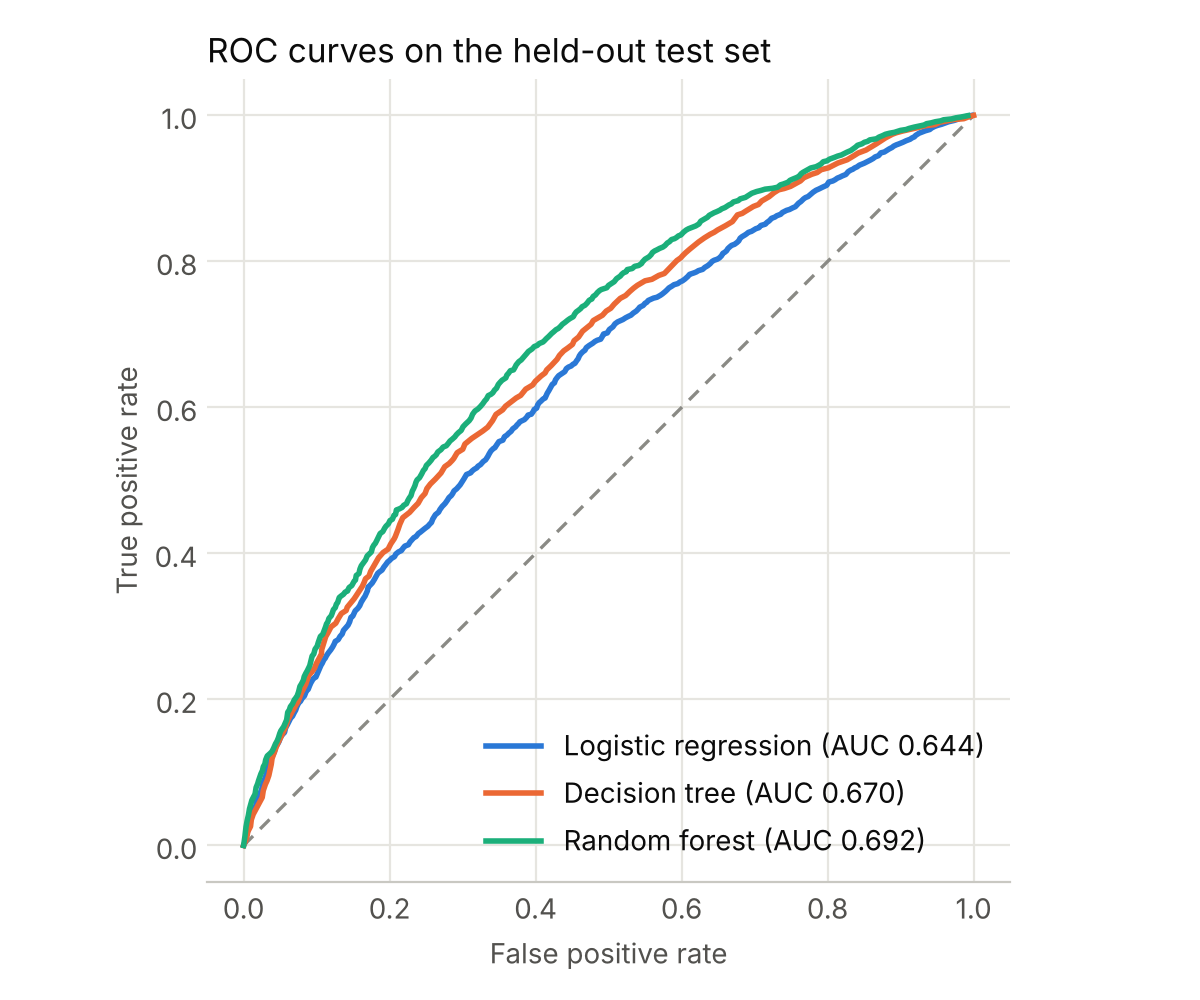

In [4]:
import pandas as pd
from IPython.display import Image, display
display(pd.read_csv('results/metrics.csv').drop(columns='best_params'))
display(Image('figures/roc.png', width=480))

### What matters most

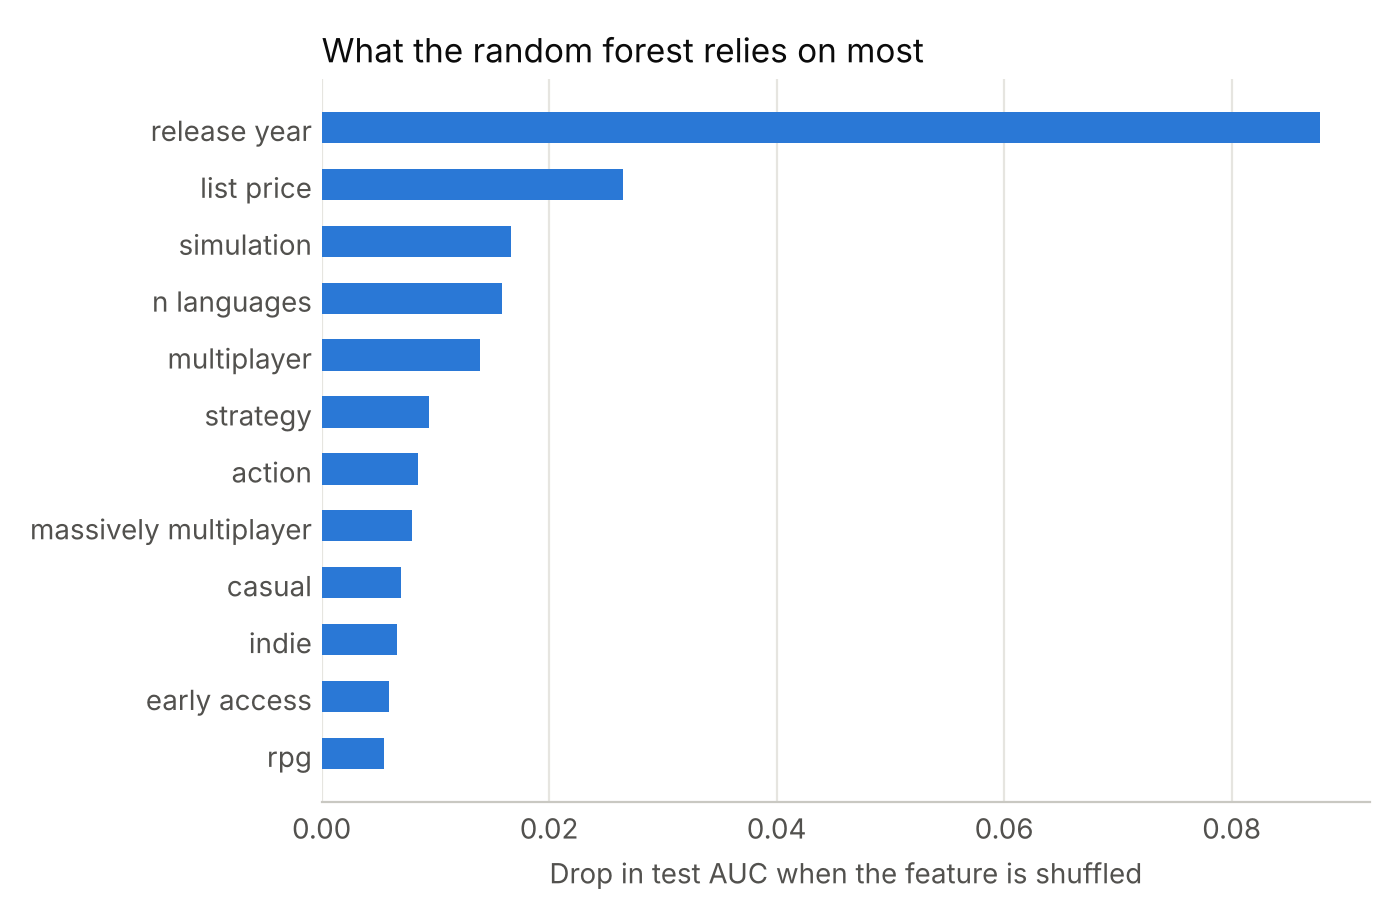

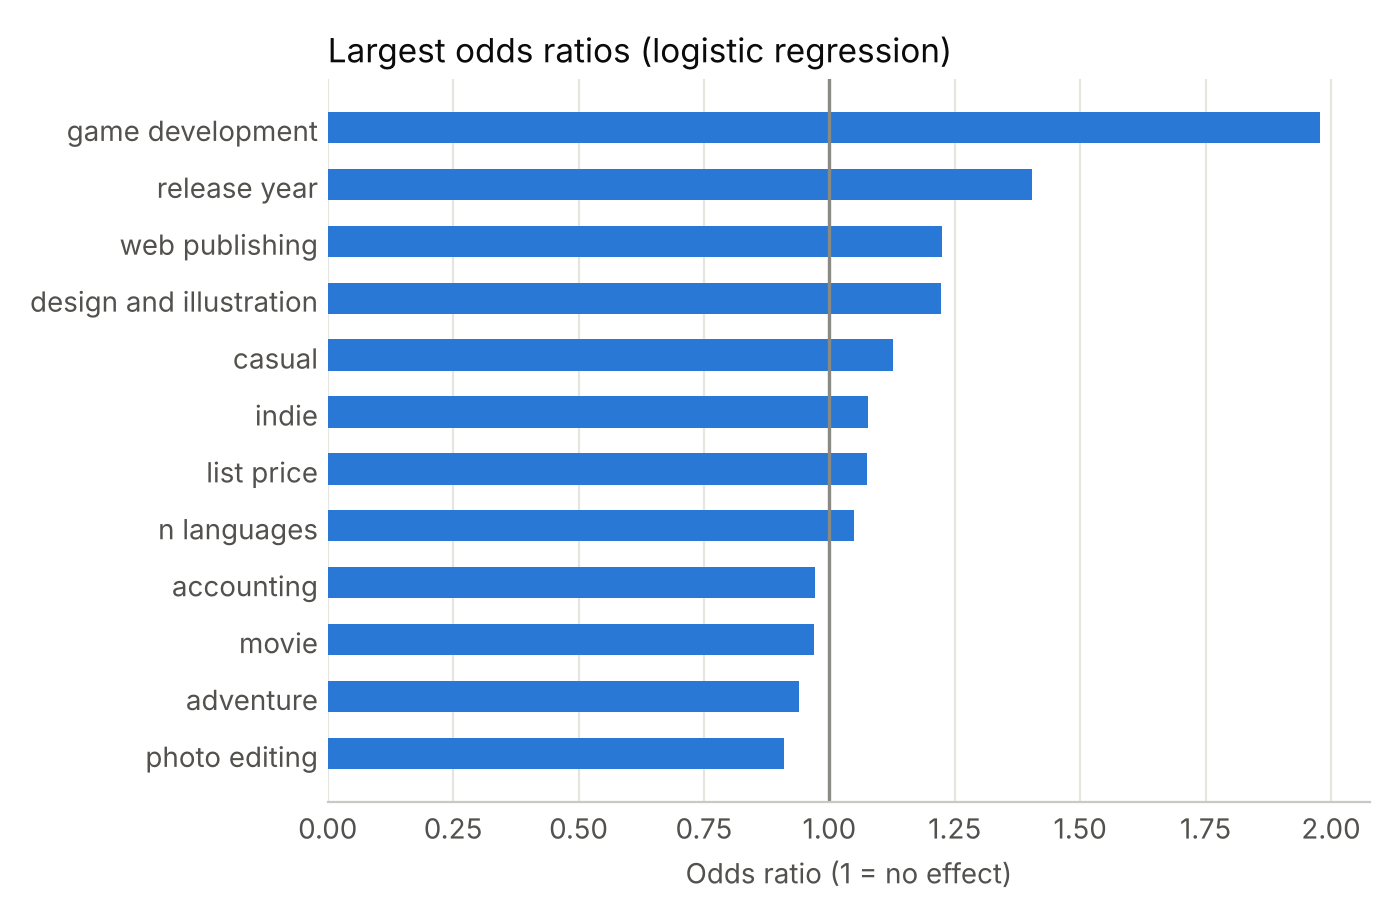

In [5]:
display(Image('figures/importance.png', width=560))
display(Image('figures/odds_ratios.png', width=560))